# S2-03 · Daily ticket history

Counts **tickets per department per day** (South African time) over the past year, fills days with no tickets with 0,
and charts the patterns the workload forecast (S2-08) learns from.

**Data:** the year of past tickets in `data/processed/combined_tickets.csv` (S1-06). It's the same file the seed script (S1-17)
loaded into the database, so this notebook needs no export and anyone can re-run it.

**Decision (Samukelo, 5 Nov):** the forecast learns from the **past tickets only**. Live tickets in Relay are still test traffic
from the team (about 1 a day), and mixing two weeks of them in would pull the forecast down by about a third.
Once Relay has real users, live tickets can be added.

**Runs in Google Colab or on a laptop:** *Run all*. The first cell finds the repo, or downloads it in Colab.

## 1. Load the past tickets

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Work from the repo root, wherever the notebook was opened from.
if Path("../../data/processed/combined_tickets.csv").exists():
    os.chdir("../..")  # opened from ml/notebooks inside the repo
elif not Path("data/processed/combined_tickets.csv").exists():
    if not Path("relay").exists():
        os.system("git clone --depth 1 https://github.com/mngadisamu/relay.git")
    os.chdir("relay")
print("Working in the repo folder:", Path.cwd().name)

DEPARTMENTS = ["HR", "IT", "Finance", "Operations"]
START, END = pd.Timestamp("2025-10-19"), pd.Timestamp("2026-10-18")  # the year of past tickets

tickets = pd.read_csv("data/processed/combined_tickets.csv", usecols=["reference", "department", "created_at"])
# created_at is stored with its time zone; turn it into the calendar day in Johannesburg.
tickets["day"] = (
    pd.to_datetime(tickets["created_at"], utc=True).dt.tz_convert("Africa/Johannesburg").dt.tz_localize(None).dt.normalize()
)
print(f"{len(tickets):,} past tickets, {tickets['day'].min().date()} to {tickets['day'].max().date()}")
tickets["department"].value_counts().reindex(DEPARTMENTS)

Working in the repo folder: relay


15,579 past tickets, 2025-10-19 to 2026-10-18


department
HR            3900
IT            3900
Finance       3900
Operations    3879
Name: count, dtype: int64

## 2. Count per day, with 0 on days with no tickets

In [2]:
days = pd.date_range(START, END, freq="D")
daily = (
    tickets.groupby(["day", "department"]).size()
    .unstack("department")
    .reindex(index=days, columns=DEPARTMENTS)
    .fillna(0)
    .astype(int)
)
daily.index.name = "day"

# Saved in the repo, so the forecast (S2-08) and its tests can use exactly these numbers.
daily.to_csv("data/processed/daily_counts.csv")
daily.head()

department,HR,IT,Finance,Operations
day,,,,
2025-10-19,1,2,1,4
2025-10-20,11,14,13,15
2025-10-21,15,14,10,19
2025-10-22,10,14,10,15
2025-10-23,14,15,15,19


## 3. Checks (S2-03 acceptance criteria)

- One row for **every** day from 19 Oct 2025 to 18 Oct 2026, with no gaps.
- Each department's daily counts **add up to its number of tickets**.

To compare with the database, run this in the Supabase SQL Editor. The numbers should match the totals printed below:

```sql
select department, count(*) from public.tickets where is_historical group by department order by department;
```

In [3]:
assert len(daily) == len(days) == 365, "A day is missing"
assert daily.index.is_monotonic_increasing and daily.index.is_unique
for dept in DEPARTMENTS:
    expected = (tickets["department"] == dept).sum()
    assert daily[dept].sum() == expected, f"{dept}: daily counts don't add up to its tickets"

print(f"{len(daily)} days, {daily.index[0].date()} to {daily.index[-1].date()}")
print("Totals:", daily.sum().to_dict(), "| all departments:", int(daily.values.sum()))
print("Days with no tickets at all:", int((daily.sum(axis=1) == 0).sum()))

365 days, 2025-10-19 to 2026-10-18
Totals: {'HR': 3900, 'IT': 3900, 'Finance': 3900, 'Operations': 3879} | all departments: 15579
Days with no tickets at all: 0


## 4. The year, week by week

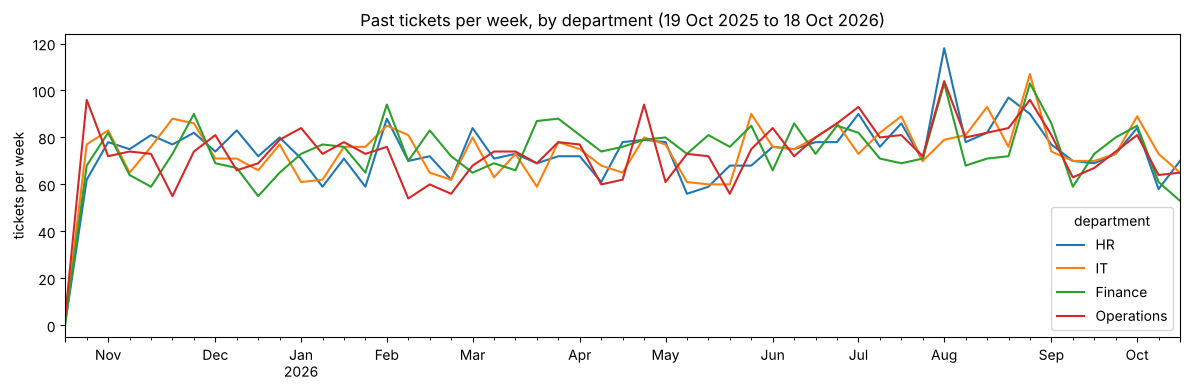

In [4]:
Path("docs/forecast").mkdir(parents=True, exist_ok=True)

weekly = daily.resample("W-SUN").sum()  # Monday to Sunday weeks
ax = weekly.plot(figsize=(12, 4), title="Past tickets per week, by department (19 Oct 2025 to 18 Oct 2026)")
ax.set_ylabel("tickets per week")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig("docs/forecast/daily-history.png", dpi=150)
plt.show()

## 5. The patterns the forecast uses

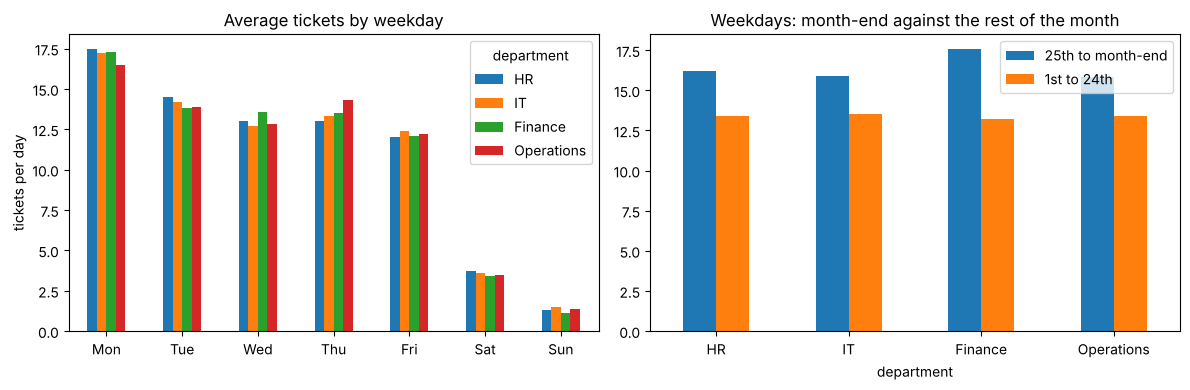

Month-end factor (25th onwards ÷ other weekdays): {'HR': 1.21, 'IT': 1.18, 'Finance': 1.33, 'Operations': 1.18}


department,HR,IT,Finance,Operations
Mon,17.5,17.2,17.3,16.5
Tue,14.5,14.2,13.8,13.9
Wed,13.0,12.7,13.6,12.8
Thu,13.0,13.3,13.5,14.3
Fri,12.0,12.4,12.1,12.2
Sat,3.7,3.6,3.4,3.5
Sun,1.3,1.5,1.1,1.4


In [5]:
# Weekday: the average number of tickets on each day of the week.
weekday = daily.groupby(daily.index.dayofweek).mean().round(1)
weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

# Month-end: weekdays from the 25th to the end of the month, against other weekdays
# (payslips and invoices make month-end busier).
weekdays_only = daily[daily.index.dayofweek < 5]
month_end = weekdays_only[weekdays_only.index.day >= 25].mean()
rest = weekdays_only[weekdays_only.index.day < 25].mean()
month_end_factor = (month_end / rest).round(2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
weekday.plot.bar(ax=axes[0], title="Average tickets by weekday")
axes[0].set_ylabel("tickets per day")
pd.DataFrame({"25th to month-end": month_end, "1st to 24th": rest}).round(1).plot.bar(
    ax=axes[1], title="Weekdays: month-end against the rest of the month"
)
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("docs/forecast/patterns.png", dpi=150)
plt.show()

print("Month-end factor (25th onwards ÷ other weekdays):", month_end_factor.to_dict())
weekday

## 6. What this means for the forecast (S2-08)

- **Weekdays drive the workload.** Mondays are the busiest day for every department; weekends are quiet. That's why the
  method averages each weekday separately instead of using one daily average.
- **Month-end is busier,** by the factor printed above (about 1.2). The method multiplies the 25th to month-end by it.
- **No gaps:** every day of the year has a count, so the method never divides by a missing day.

**Honest limits (say these to the panel):** the dates in this history were *assigned* to the past tickets in S1-06, with a
realistic pattern (busier Mondays, month-end and winter), not recorded at Kopano Freight. The forecast shows how Relay's
method works; its numbers aren't a prediction of the real company.